In [33]:
# Importing the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import pyarrow

from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

In [34]:
# Load daily basin
df = pd.read_parquet(r"data\model_dfs\basin_daily_model.parquet")

In [35]:
# make sure date is datetime
df['date'] = pd.to_datetime(df['date'])

# day of year
df['doy'] = df['date'].dt.dayofyear



In [36]:
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.month

#df['snow_month'] = df['month'].isin([11, 12, 1, 2, 3, 4, 5]).astype(int)


In [37]:
# isolate prediction features and y
features = [
    'temp_mean',
    'temp_14d_mean',
    'precip_7d',
    'precip_14d',
    'precip_30d',
    'doy_sin',
    'doy_cos'
]

df = df[
    ['date', 'basin_swe'] + features
].dropna().copy()

X = df[features]
y = df['basin_swe']

In [38]:
# split test train data and scale
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0
)

X_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

In [39]:
# scale y
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

In [40]:
# svr model
svr = SVR(
    kernel='rbf',
    C=10,
    gamma='scale',
    epsilon=0.1
)

svr.fit(
    X_train_scaled,
    y_train_scaled
)

SVR(C=10)

In [41]:
# pred
y_pred_scaled = svr.predict(
    X_test_scaled
)

y_pred = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

In [42]:
# calc mse, rmse, r2
mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1.26766421290844
RMSE: 2.1239852569963467
R²: 0.8959129473983319


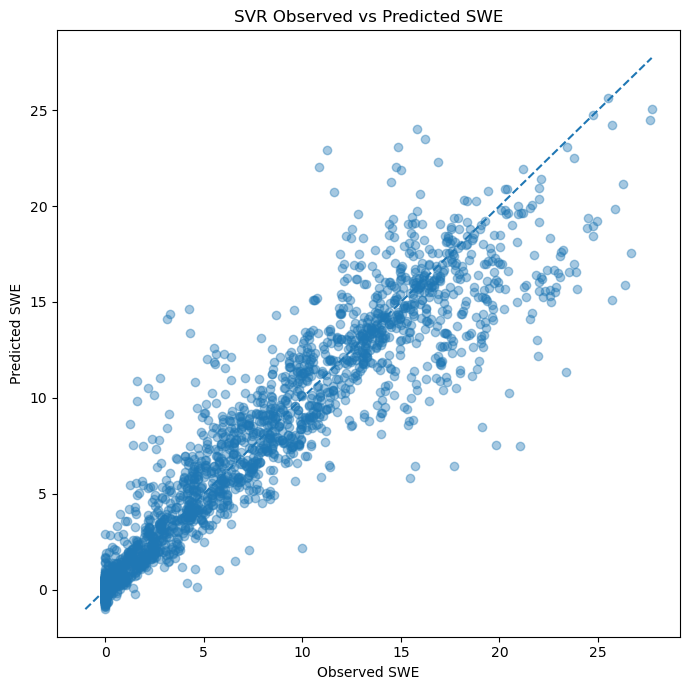

In [43]:
# plot observed vs predicted
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

lims = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(
    lims,
    lims,
    '--'
)

plt.xlabel('Observed SWE')
plt.ylabel('Predicted SWE')
plt.title('SVR Observed vs Predicted SWE')

plt.tight_layout()
plt.show()

In [44]:
# create cross validation
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [1, 10, 50, 100],
    'gamma': ['scale', 0.01, 0.1, 1],
    'epsilon': [0.01, 0.1, 0.25, 0.5]
}

grid_svr = GridSearchCV(
    SVR(kernel='rbf'),
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)

grid_svr.fit(
    X_train_scaled,
    y_train_scaled
)

print("Best parameters:", grid_svr.best_params_)
print("Best CV RMSE:",
      -grid_svr.best_score_)

Best parameters: {'C': 10, 'epsilon': 0.01, 'gamma': 1}
Best CV RMSE: 0.29632408177803915


In [45]:
# use best svr parameters for estimator
best_svr = grid_svr.best_estimator_

y_pred_scaled = best_svr.predict(
    X_test_scaled
)

y_pred = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

print(
    "MAE:",
    mean_absolute_error(y_test, y_pred)
)

print(
    "RMSE:",
    np.sqrt(
        mean_squared_error(
            y_test,
            y_pred
        )
    )
)

print(
    "R²:",
    r2_score(y_test, y_pred)
)

MAE: 1.0293786352931134
RMSE: 1.9413230985404173
R²: 0.9130460412163582


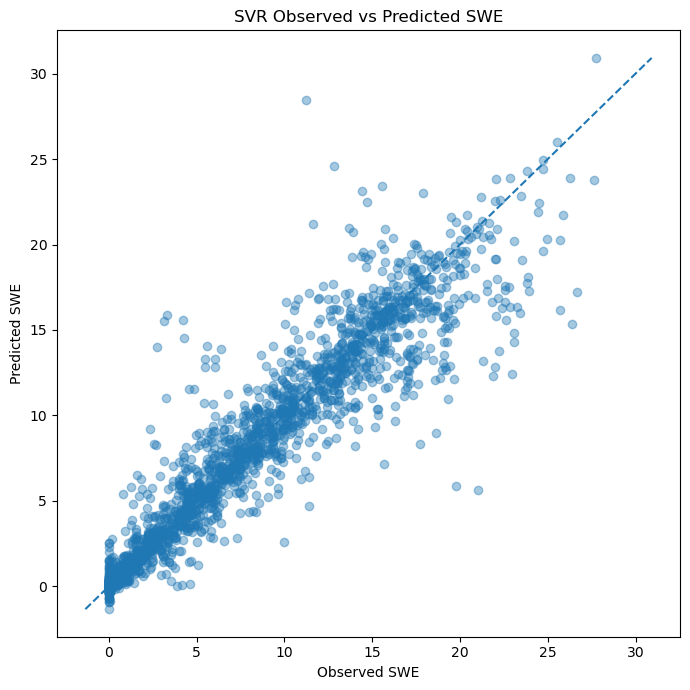

In [48]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

lims = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(
    lims,
    lims,
    '--'
)

plt.xlabel('Observed SWE')
plt.ylabel('Predicted SWE')
plt.title('SVR Observed vs Predicted SWE')

plt.tight_layout()

plt.savefig(
    "figures/svr_observed_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



SAVE MODEL

In [46]:
import joblib
from pathlib import Path

model_dir = Path("data/models")
model_dir.mkdir(parents=True, exist_ok=True)

svr_bundle = {
    "model": best_svr,
    "x_scaler": X_scaler,
    "y_scaler": y_scaler,
    "features": features
}

joblib.dump(
    svr_bundle,
    model_dir / "svr_swe_bundle.joblib"
)

print("SVR bundle saved.")

SVR bundle saved.


To relaod and future RCP data

In [ ]:
bundle = joblib.load(
    "data/models/svm_low_snow_bundle.joblib"
)

best_svm = bundle["model"]
scaler = bundle["scaler"]
features = bundle["features"]

In [ ]:
X_future = future_df[features]

X_future_scaled = scaler.transform(X_future)

future_df['predicted_low_snow'] = (
    best_svm.predict(X_future_scaled)
)